# AI-Based Traffic Sign Recognition Using Artificial Neural Networks
**Single-file project notebook.** Dataset: GTSRB. Model: Multilayer Perceptron (Dense layers only, 



**Dataset downloaded link:** https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

In [1]:
import os
print(os.getcwd())
print(os.listdir("."))
print(os.listdir("data"))

d:\BS-AI\Artificial Neural Networks\Artificial Neural Networks-Lab\project1
['data', 'Meta.csv', 'README.md', 'traffic-sign-ann', 'traffic-sign-ann.zip', 'Traffic_Sign_Recognition_MLP.ipynb']
['.gitkeep', 'GTSRB_Final_Training_Images.zip']


In [5]:
%pip install gradio

  Using cached gradio-6.30.0-py3-none-any.whl.metadata (16 kB)
  Using cached gradio_client-2.7.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached groovy-0.1.2-py3-none-any.whl.metadata (6.1 kB)
  Using cached hf_gradio-0.4.1-py3-none-any.whl.metadata (428 bytes)
  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)
  Using cached pydub-0.25.1-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached safehttpx-0.1.7-py3-none-any.whl.metadata (4.2 kB)
  Using cached semantic_version-2.10.0-py2.py3-none-any.whl.metadata (9.7 kB)
  Using cached tomlkit-0.14.0-py3-none-any.whl.metadata (2.8 kB)
  Using cached typer-0.27.3-py3-none-any.whl.metadata (16 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
  Using cached opentelemetry_api-1.45.1-py3

  You can safely remove it manually.


## The 43 sign names


In [1]:
# class_names.py
# The 43 traffic sign names of GTSRB.
# The position in the list is the class id (0 to 42), the same id used in Train.csv and Test.csv.

class_names = [
    "Speed limit (20 km/h)",                                  # 0
    "Speed limit (30 km/h)",                                  # 1
    "Speed limit (50 km/h)",                                  # 2
    "Speed limit (60 km/h)",                                  # 3
    "Speed limit (70 km/h)",                                  # 4
    "Speed limit (80 km/h)",                                  # 5
    "End of speed limit (80 km/h)",                           # 6
    "Speed limit (100 km/h)",                                 # 7
    "Speed limit (120 km/h)",                                 # 8
    "No passing",                                             # 9
    "No passing for vehicles over 3.5 tons",                  # 10
    "Right-of-way at the next intersection",                  # 11
    "Priority road",                                          # 12
    "Yield",                                                  # 13
    "Stop",                                                   # 14
    "No vehicles",                                            # 15
    "Vehicles over 3.5 tons prohibited",                      # 16
    "No entry",                                               # 17
    "General caution",                                        # 18
    "Dangerous curve to the left",                            # 19
    "Dangerous curve to the right",                           # 20
    "Double curve",                                           # 21
    "Bumpy road",                                             # 22
    "Slippery road",                                          # 23
    "Road narrows on the right",                              # 24
    "Road work",                                              # 25
    "Traffic signals",                                        # 26
    "Pedestrians",                                            # 27
    "Children crossing",                                      # 28
    "Bicycles crossing",                                      # 29
    "Beware of ice/snow",                                     # 30
    "Wild animals crossing",                                  # 31
    "End of all speed and passing limits",                    # 32
    "Turn right ahead",                                       # 33
    "Turn left ahead",                                        # 34
    "Ahead only",                                             # 35
    "Go straight or right",                                   # 36
    "Go straight or left",                                    # 37
    "Keep right",                                             # 38
    "Keep left",                                              # 39
    "Roundabout mandatory",                                   # 40
    "End of no passing",                                      # 41
    "End of no passing by vehicles over 3.5 tons",            # 42
]

---
# PART 1 - Environment test (Stage 1)

In [6]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn
import PIL
import tensorflow as tf
import gradio as gr

print("Python:", sys.version)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("pillow:", PIL.__version__)
print("tensorflow:", tf.__version__)
print("gradio:", gr.__version__)
print("All libraries imported successfully")

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
numpy: 1.26.4
pandas: 3.0.6
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1
pillow: 13.0.0
tensorflow: 2.17.1
gradio: 6.30.0
All libraries imported successfully


---
# PART 2 - Load and prepare the images (Stage 2-3)

**Goal:** turn the GTSRB images into numbers the neural network can use.

1. Check the dataset is in the `data` folder
2. Read `Train.csv` (a table with the image path and the class id of every image)
3. Load each image, **resize to 32 x 32**, and **normalize** pixel values to 0-1
4. Split into **training** and **validation** sets
5. Save the arrays so we never have to load the images again


In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

## Step 1: Check the dataset folder


In [18]:
data_folder = "data"

print("Train.csv exists:", os.path.exists(os.path.join(data_folder, "Train.csv")))
print("Test.csv exists:", os.path.exists(os.path.join(data_folder, "Test.csv")))
print("Train folder exists:", os.path.isdir(os.path.join(data_folder, "Train")))
print("Test folder exists:", os.path.isdir(os.path.join(data_folder, "Test")))

Train.csv exists: True
Test.csv exists: True
Train folder exists: True
Test folder exists: True


## Step 2: Look at the training table
`ClassId` is the correct answer (0 to 42). `Path` tells us where the image file is inside the `data` folder.

In [21]:
df_train = pd.read_csv("data/Train.csv")

In [10]:
df_train.head()

,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22


In [11]:
df_train.shape

(43, 5)

In [22]:
df_train.isnull().sum()

Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Number of classes: 43


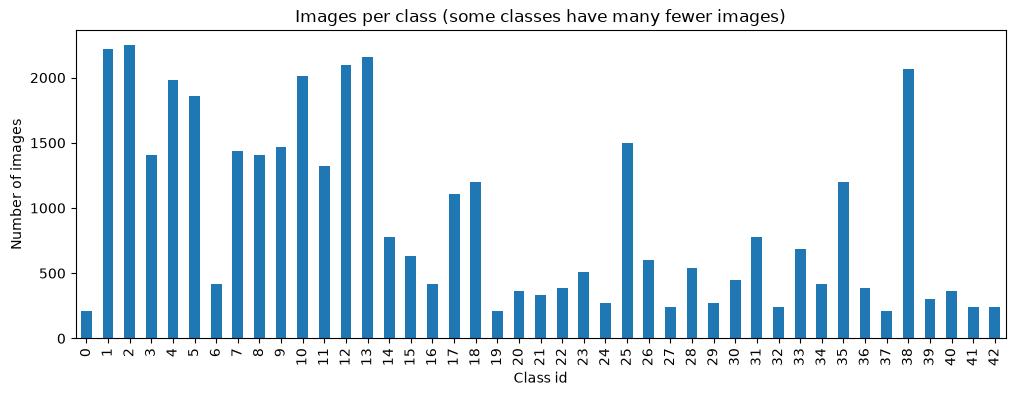

In [23]:
print("Number of classes:", df_train["ClassId"].nunique())

df_train["ClassId"].value_counts().sort_index().plot(kind="bar", figsize=(12, 4))
plt.xlabel("Class id")
plt.ylabel("Number of images")
plt.title("Images per class (some classes have many fewer images)")
plt.show()

## Step 3: Check that one image path really works


In [24]:
first_path = os.path.join(data_folder, df_train["Path"][0])
print(first_path)
print("File exists:", os.path.exists(first_path))

data\Train/20/00020_00000_00000.png
File exists: True


## Step 4: Load, resize and normalize the images



In [25]:
image_size = 32

def load_images(df):
    images = []
    for i in range(len(df)):
        path = os.path.join(data_folder, df["Path"][i])
        img = Image.open(path).convert("RGB")
        img = img.resize((image_size, image_size))
        images.append(np.array(img))
        if (i + 1) % 5000 == 0:
            print("loaded", i + 1, "images")
    return np.array(images)

In [26]:
X = load_images(df_train)
y = df_train["ClassId"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

loaded 5000 images
loaded 10000 images
loaded 15000 images
loaded 20000 images
loaded 25000 images
loaded 30000 images
loaded 35000 images
X shape: (39209, 32, 32, 3)
y shape: (39209,)


**Normalize:** pixels are 0 to 255. Dividing by 255 makes them 0 to 1, which helps the network train faster and more steadily.

In [27]:
X = X.astype("float32") / 255.0

print("smallest pixel value:", X.min())
print("largest pixel value:", X.max())

smallest pixel value: 0.0
largest pixel value: 1.0


## Step 5: Split into training and validation
- **Training set (80%)**:  **Validation set (20%)**
- `stratify=y` keeps the same class proportions in both sets.
-

In [28]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)

Training images: (31367, 32, 32, 3)
Validation images: (7842, 32, 32, 3)


In [29]:
# free some memory, we do not need the full X any more
del X

## Step 6: Load the official test set


In [30]:
df_test = pd.read_csv("data/Test.csv")
X_test = load_images(df_test)
X_test = X_test.astype("float32") / 255.0
y_test = df_test["ClassId"].values

print("Test images:", X_test.shape)

loaded 5000 images
loaded 10000 images
Test images: (12630, 32, 32, 3)


## Step 7: Save the prepared data
`

In [31]:
os.makedirs("saved_data", exist_ok=True)

np.save("saved_data/X_train.npy", X_train)
np.save("saved_data/y_train.npy", y_train)
np.save("saved_data/X_val.npy", X_val)
np.save("saved_data/y_val.npy", y_val)
np.save("saved_data/X_test.npy", X_test)
np.save("saved_data/y_test.npy", y_test)

print("Saved to the saved_data folder")

Saved to the saved_data folder


## Step 8: Test the loader
Check the shapes and look at some images with their labels. **The title must match what the picture shows.** 

In [32]:
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val  :", X_val.shape, "y_val  :", y_val.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)
print("pixel range:", X_train.min(), "to", X_train.max())
print("label range:", y_train.min(), "to", y_train.max())

X_train: (31367, 32, 32, 3) y_train: (31367,)
X_val  : (7842, 32, 32, 3) y_val  : (7842,)
X_test : (12630, 32, 32, 3) y_test : (12630,)
pixel range: 0.0 to 1.0
label range: 0 to 42


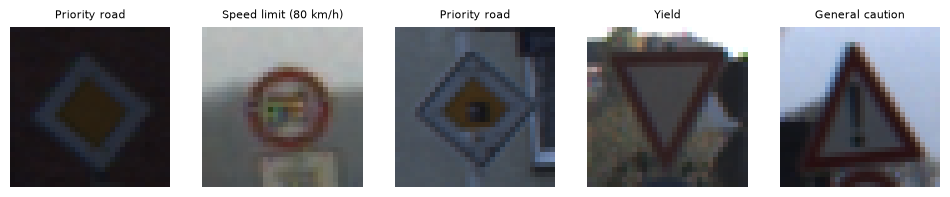

In [33]:
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis("off")
plt.show()

---
# PART 3 - Build and train the MLP (Stage 4)

We build a **fully connected feed-forward neural network** (Multilayer Perceptron). 

```
Flatten -> Dense(128, ReLU) -> Dense(64, ReLU) -> Dense(43, Softmax)
```

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [35]:
# makes the results repeatable
keras.utils.set_random_seed(42)

## Step 1: Load the prepared data from Stage 2-3

In [36]:
X_train = np.load("saved_data/X_train.npy")
y_train = np.load("saved_data/y_train.npy")
X_val = np.load("saved_data/X_val.npy")
y_val = np.load("saved_data/y_val.npy")

num_classes = int(y_train.max()) + 1

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("number of classes:", num_classes)

X_train: (31367, 32, 32, 3)
X_val: (7842, 32, 32, 3)
number of classes: 43


## Step 2: Build the model

| Layer | What it does |
|---|---|
| `Flatten` | Turns the 32 x 32 x 3 image into one long list of 3072 numbers. |
| `Dense(128, relu)` | 128 neurons. Each one looks at all 3072 numbers and learns a pattern. |
| `Dense(64, relu)` | 64 neurons that combine the patterns of the previous layer. |
| `Dense(43, softmax)` | 43 output neurons, one per sign. Softmax makes them 43 probabilities that add up to 1. |

**ReLU** (activation function): keeps positive numbers, turns negative numbers into 0. Without an activation function, the network could only learn straight-line patterns.

In [37]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax"),
])

In [38]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 43)             │         2,795 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 404,395 (1.54 MB)

 Trainable params: 404,395 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

## Step 3: Compile the model



In [39]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

## Step 4: Train

- **epoch** = one full pass over all training images
- **batch_size** = how many images are used before the weights are updated once
- `validation_data` = after each epoch, the model is also tested on the validation images (it does not learn from them)



In [40]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
)

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.4202 - loss: 2.2561 - val_accuracy: 0.6364 - val_loss: 1.3595
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7244 - loss: 1.0557 - val_accuracy: 0.7567 - val_loss: 0.9070
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.8108 - loss: 0.7275 - val_accuracy: 0.8067 - val_loss: 0.7021
Epoch 4/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8464 - loss: 0.5878 - val_accuracy: 0.8111 - val_loss: 0.6480
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8697 - loss: 0.4989 - val_accuracy: 0.8446 - val_loss: 0.5634
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8875 - loss: 0.4373 - val_accuracy: 0.8513 - val_loss: 0.5443
Epoch 7/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8974 - loss: 0.3960 - val_accuracy: 0.8768 - val_loss: 0.4620
Epoch 8/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9032 - loss: 0.3702 - val_acc

In [41]:
print("Final training accuracy  :", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

Final training accuracy  : 0.9482258558273315
Final validation accuracy: 0.9178780913352966


## Step 5: Accuracy and loss graphs
.

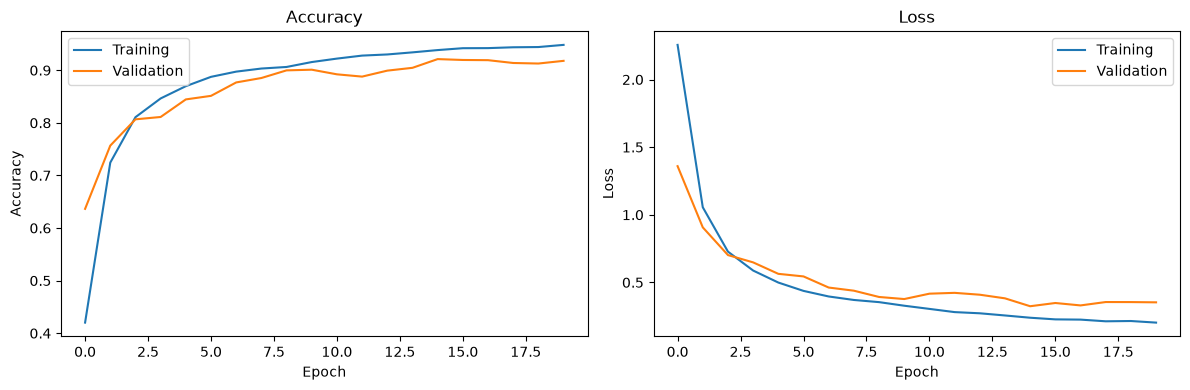

In [42]:
os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("outputs/accuracy_loss.png")
plt.show()

## Step 6: Save the model and the training history

In [43]:
os.makedirs("models", exist_ok=True)
model.save("models/traffic_sign_mlp.keras")

pd.DataFrame(history.history).to_csv("saved_data/history.csv", index=False)

print("Model saved to models/traffic_sign_mlp.keras")

Model saved to models/traffic_sign_mlp.keras


---
# PART 4 - Evaluate the model (Stage 5)

We test the saved model on the **test set**, images it never used for training or validation.


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [45]:
model = keras.models.load_model("models/traffic_sign_mlp.keras")

X_test = np.load("saved_data/X_test.npy")
y_test = np.load("saved_data/y_test.npy")

print("Test images:", X_test.shape)

Test images: (12630, 32, 32, 3)


## Step 1: Predict the test images
`model.predict` gives 43 probabilities per image. `np.argmax` picks the class with the highest probability.

In [46]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

print("Predictions:", y_pred.shape)

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Predictions: (12630,)


## Step 2: Accuracy, precision, recall, F1-score



In [47]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)",
               "Precision (macro)", "Recall (macro)", "F1-score (macro)"],
    "Value": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="weighted", zero_division=0),
        recall_score(y_test, y_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred, average="weighted", zero_division=0),
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0),
    ],
})

results

,Metric,Value
0,Accuracy,0.824307
1,Precision (weighted),0.841918
2,Recall (weighted),0.824307
3,F1-score (weighted),0.820060
4,Precision (macro),0.833174
5,Recall (macro),0.763203
6,F1-score (macro),0.778385


In [48]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      0.28      0.44        60
           1       0.72      0.89      0.80       720
           2       0.92      0.79      0.85       750
           3       0.99      0.44      0.61       450
           4       0.86      0.80      0.83       660
           5       0.65      0.86      0.74       630
           6       0.94      0.77      0.85       150
           7       0.85      0.74      0.79       450
           8       0.82      0.84      0.83       450
           9       0.97      0.67      0.79       480
          10       0.69      0.97      0.81       660
          11       0.69      0.92      0.79       420
          12       0.87      0.98      0.92       690
          13       0.97      0.96      0.97       720
          14       0.81      0.99      0.89       270
          15       0.91      0.93      0.92       210
          16       1.00      0.97      0.98       150
          17       0.98    

## Step 3: Confusion matrix


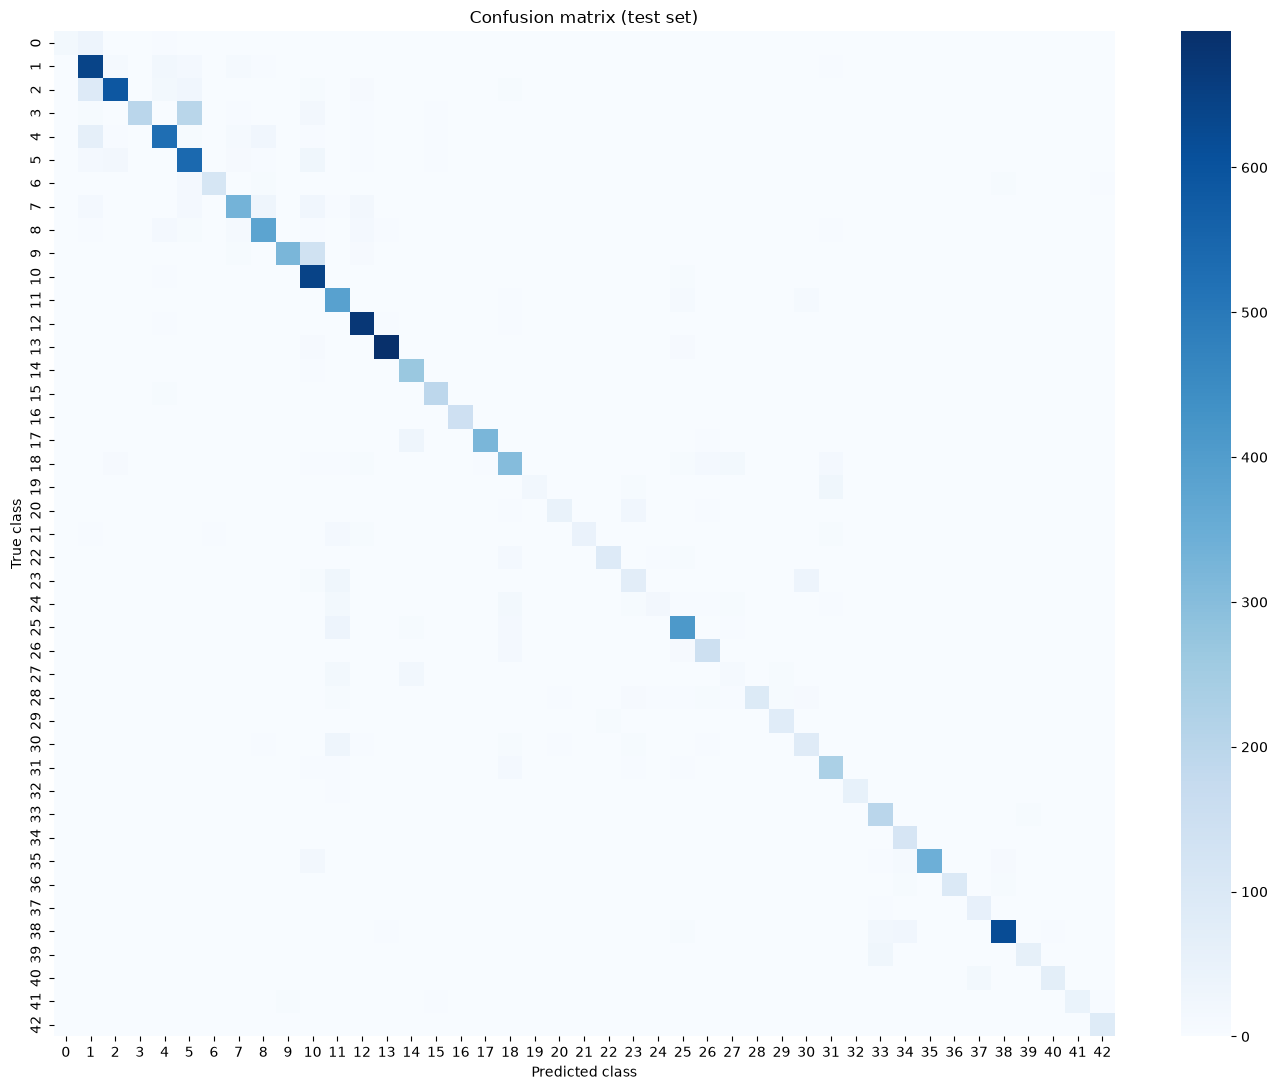

In [49]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 11))
sns.heatmap(cm, cmap="Blues")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png")
plt.show()

## Step 4: Which signs are hardest?
Recall per class = correct predictions of that class divided by all real images of that class. The lowest ones are the signs the model finds hardest.

In [50]:
class_totals = np.maximum(cm.sum(axis=1), 1)
class_recall = cm.diagonal() / class_totals

per_class = pd.DataFrame({
    "Class id": range(len(class_recall)),
    "Sign": class_names[:len(class_recall)],
    "Recall": class_recall,
})

per_class.sort_values("Recall").head(5)

,Class id,Sign,Recall
27,27,Pedestrians,0.183333
24,24,Road narrows on the right,0.233333
0,0,Speed limit (20 km/h),0.283333
19,19,Dangerous curve to the left,0.383333
3,3,Speed limit (60 km/h),0.440000


## Step 5: Accuracy and loss graph (from training)

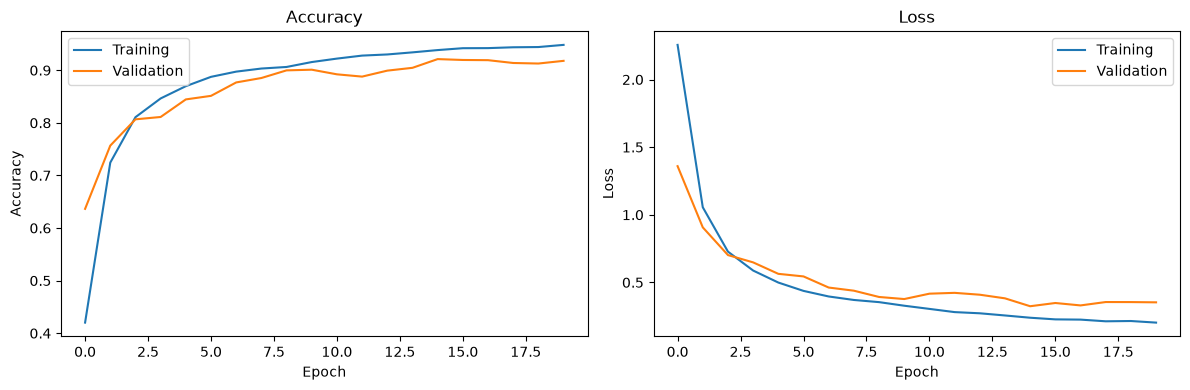

In [51]:
history = pd.read_csv("saved_data/history.csv")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["accuracy"], label="Training")
plt.plot(history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["loss"], label="Training")
plt.plot(history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("outputs/accuracy_loss.png")
plt.show()

---
# PART 5 - Predict one image (Stage 6)

We load the saved model, choose one image, and print the predicted sign and the confidence.

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow import keras

In [53]:
model = keras.models.load_model("models/traffic_sign_mlp.keras")
print("Model loaded")

Model loaded


## Step 1: Choose an image
**Option A :** type the path of an image.The default is the first test image that comes with the dataset: `data/Test/00000.png`.

In [54]:
image_path = "data/Test/00000.png"

**Option B (optional): open a file picker window.** Run this cell instead of Option A if you want to click and choose a file. 

In [55]:
from tkinter import Tk, filedialog

window = Tk()
window.withdraw()
window.attributes("-topmost", True)
image_path = filedialog.askopenfilename(
    title="Select a traffic sign image",
    filetypes=[("Images", "*.png *.jpg *.jpeg *.ppm")],
)
window.destroy()

print("You selected:", image_path)

You selected: D:/BS-AI/Artificial Neural Networks/Artificial Neural Networks-Lab/project1/data/Test/00006.png


## Step 2: Prepare the image exactly like the training images
Resize to 32 x 32, scale to 0-1, and add an extra dimension because the model expects a **batch** of images (shape 1 x 32 x 32 x 3).

In [56]:
img = Image.open(image_path).convert("RGB")
img_small = img.resize((32, 32))

x = np.array(img_small, dtype="float32") / 255.0
x = np.expand_dims(x, axis=0)

print("Input shape:", x.shape)

Input shape: (1, 32, 32, 3)


## Step 3: Predict

In [57]:
probs = model.predict(x)[0]

best = np.argmax(probs)
confidence = probs[best] * 100

print("Predicted class id:", best)
print("Predicted sign    :", class_names[best])
print("Confidence        : {:.1f}%".format(confidence))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
Predicted class id: 18
Predicted sign    : General caution
Confidence        : 100.0%


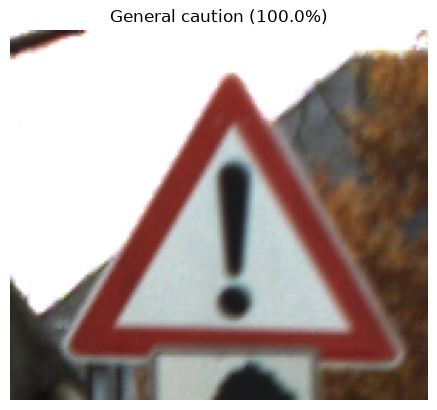

In [58]:
plt.imshow(img)
plt.title("{} ({:.1f}%)".format(class_names[best], confidence))
plt.axis("off")
plt.show()

## Step 4: Top 3 guesses

In [59]:
top3 = np.argsort(probs)[::-1][:3]

for i in top3:
    print("{:5.1f}%  {}".format(probs[i] * 100, class_names[i]))

100.0%  General caution
  0.0%  Traffic signals
  0.0%  Pedestrians


---
# PART 6 - Gradio interface (Stage 7)


In [60]:
import numpy as np
import gradio as gr
from tensorflow import keras

gradio_model = keras.models.load_model("models/traffic_sign_mlp.keras")

def predict_sign(image):
    if image is None:
        return {}
    image = image.convert("RGB")                    # make sure it has 3 colour channels
    image = image.resize((32, 32))                  # same size as the training images
    x = np.array(image, dtype="float32") / 255.0    # pixel values 0 to 1
    x = np.expand_dims(x, axis=0)                   # a batch of one image: (1, 32, 32, 3)
    probs = gradio_model.predict(x, verbose=0)[0]   # 43 probabilities
    return {class_names[i]: float(probs[i]) for i in range(len(class_names))}

demo = gr.Interface(
    fn=predict_sign,
    inputs=gr.Image(type="pil", label="Upload a traffic sign image"),
    outputs=gr.Label(num_top_classes=3, label="Prediction (top 3 with confidence)"),
    title="Traffic Sign Recognition (MLP)",
    description="Upload a German traffic sign image. The Multilayer Perceptron predicts which sign it is.",
)

In [61]:
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


**Done when:** an uploaded image shows a sign name and a confidence in the browser.

---
# PART 7 (optional) - Logistic Regression baseline (Stage 8-9)

A **baseline** is a simple model we compare against. If our MLP beats it, the extra hidden layers are helping.

Logistic regression has **no hidden layers**: it directly draws straight-line boundaries between classes on the 3072 pixel numbers.

To keep it fast, we train it on the first 10,000 training images only. Say this in your report, because it makes the comparison not perfectly fair. We test both models on the same full test set.

In [ ]:
import numpy as np
import pandas as pd
from tensorflow import keras
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

In [ ]:
X_train = np.load("saved_data/X_train.npy")
y_train = np.load("saved_data/y_train.npy")
X_test = np.load("saved_data/X_test.npy")
y_test = np.load("saved_data/y_test.npy")

# Logistic regression needs a flat table: one row per image, 3072 columns
n = min(10000, len(X_train))
X_train_flat = X_train[:n].reshape(n, -1)
y_train_small = y_train[:n]
X_test_flat = X_test.reshape(len(X_test), -1)

print("Training table:", X_train_flat.shape)
print("Test table    :", X_test_flat.shape)

This step can take a few minutes. A warning about `max_iter` or convergence is normal.

In [ ]:
lr_model = LogisticRegression(max_iter=100)
lr_model.fit(X_train_flat, y_train_small)

In [ ]:
y_pred_lr = lr_model.predict(X_test_flat)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted", zero_division=0)

print("Logistic Regression accuracy:", lr_accuracy)
print("Logistic Regression F1 (weighted):", lr_f1)

## Compare with the MLP
We load the saved MLP and score it on the same test images.

In [ ]:
mlp_model = keras.models.load_model("models/traffic_sign_mlp.keras")

y_pred_mlp = np.argmax(mlp_model.predict(X_test), axis=1)

mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
mlp_f1 = f1_score(y_test, y_pred_mlp, average="weighted", zero_division=0)

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression (first 10,000 train images)", "MLP (all training images)"],
    "Accuracy": [lr_accuracy, mlp_accuracy],
    "F1 (weighted)": [lr_f1, mlp_f1],
})

comparison

---
# PART 8 - Notes for your report and presentation

## Course concepts in simple words
- **Supervised learning:** we train with images **and** their correct labels (`ClassId` in `Train.csv`).
- **Multiclass classification:** 43 possible answers. The last layer uses **Softmax** to give 43 probabilities that add up to 1; the biggest is the prediction and its value is the confidence.
- **Feed-forward neural network (MLP):** information flows one way, input -> hidden layers -> output. `Dense` means every neuron connects to every neuron in the next layer. `Flatten` turns the image into 3072 numbers. **ReLU** turns negatives into 0 so the network can learn non-linear patterns.
- **Loss function:** a number saying how wrong the model is. We use sparse categorical cross-entropy; it is small when the correct class gets a high probability.
- **Backpropagation:** after each batch, the error is sent backwards through the layers to find how much each weight contributed. The **Adam optimizer** then nudges the weights to reduce the loss. This all happens inside `model.fit(...)`.
- **Model evaluation:** validation set (watch for overfitting during training), test set (final score), accuracy, precision, recall, F1-score, confusion matrix.

## Limitations to mention
- An MLP ignores where pixels are in the picture, so it is usually weaker on images than a CNN (future work).
- 32 x 32 images lose fine details.
- The model only knows the 43 German sign types; any other image is forced into one of them.
- Some classes have far fewer images than others.

## Fill in with **your own** results (from Part 4)
Accuracy: ______   Precision (weighted): ______   Recall (weighted): ______   F1 (weighted): ______

## Likely presentation questions
- **Why an MLP and not a CNN?** The course covers fully connected feed-forward networks. A CNN is future work.
- **Why resize to 32 x 32?** Same input size for every image, fewer weights, faster training.
- **Why divide by 255?** Pixels are 0-255; 0-1 makes training steadier and faster.
- **Why a validation set?** To check on unseen data during training and notice overfitting.
- **What does Softmax do?** Turns 43 raw outputs into probabilities that sum to 1.
- **What does Adam do?** Updates the weights using the gradients from backpropagation, adapting the step size automatically.

*Optional Flask backend:* see `app_flask.py` in the zip (only after everything above works).